# Τα ελάφια του δάσους: χτίζουμε και ξαναχτίζουμε ένα μοντέλο

**Πώς δουλεύουμε**
1. Πατάμε το κουμπί ▶ δίπλα σε κάθε κελί, **με τη σειρά** που λέει το φύλλο εργασίας.
2. Το πρώτο κελί με τίτλο «Κελί ρυθμίσεων» το εκτελούμε μία φορά στην αρχή και **δεν το αλλάζουμε**.
3. Οι γραμμές που έχουν το σχόλιο `# ΑΛΛΑΞΕ ΕΔΩ` είναι δικές σας. Εκεί γράφετε τις ιδέες της ομάδας.
4. Για δεκαδικούς αριθμούς χρησιμοποιούμε **τελεία**: `0.03` (όχι `0,03`).
5. Αν κάτι χαλάσει, διαβάζουμε το μήνυμα λάθους. Μετά πατάμε ▶ ξανά ή ρωτάμε τον/την ερευνήτρια.

***μη χρησιμοποιείτε «Εκτέλεση όλων». η «Βοήθεια Γ» έχει κενά που συμπληρώνονται.***

## Κελί ρυθμίσεων (εκτελείται μία φορά, δεν αλλάζει. )
## Εκτελέστε το ΤΩΡΑ ΣΤΗΝ ΑΡΧΗ μια φορά

---



In [ ]:
# ΜΗΝ ΑΛΛΑΞΕΙΣ ΤΙΠΟΤΑ ΣΕ ΑΥΤΟ ΤΟ ΚΕΛΙ. Εκτέλεσέ το μία φορά, στην αρχή.
import random
import matplotlib.pyplot as plt


def trexe(neos_plithismos, etoi=100, arxiko=1300, ekteleseis=1):
    """Τρέχει το μοντέλο για etoi έτη, ζωγραφίζει γράφημα και τυπώνει αποτελέσματα."""
    istorika = []
    for k in range(ekteleseis):
        plithismos = arxiko
        istoriko = [plithismos]
        for etos in range(etoi):
            plithismos = neos_plithismos(plithismos)
            istoriko.append(plithismos)
        istorika.append(istoriko)

    for istoriko in istorika:
        plt.plot(istoriko, alpha=1 if ekteleseis == 1 else 0.4)
    plt.xlabel("Έτη από το 2000")
    plt.ylabel("Ελάφια")
    plt.grid(alpha=0.3)
    plt.show()

    for etos in sorted(set([50, etoi])):
        if etos > etoi:
            continue
        times = [istoriko[etos] for istoriko in istorika]
        if ekteleseis == 1:
            print("Το", 2000 + etos, ":", round(times[0]), "ελάφια")
        else:
            print("Το", 2000 + etos, ": μέσος όρος", round(sum(times) / len(times)),
                  "ελάφια (από", round(min(times)), "έως", round(max(times)), ")")
    if min(min(istoriko) for istoriko in istorika) < 0:
        print("Προσοχή: ο πληθυσμός έγινε αρνητικός. Έχει νόημα αυτό για τα ελάφια;")


def statistika(neos_plithismos, ekteleseis=200, etoi=100, arxiko=1300):
    """Τρέχει το μοντέλο πολλές φορές και δείχνει μέσο όρο και εύρος (χωρίς γράφημα)."""
    for etos in sorted(set([50, etoi])):
        if etos > etoi:
            continue
        times = []
        for k in range(ekteleseis):
            plithismos = arxiko
            for e in range(etos):
                plithismos = neos_plithismos(plithismos)
            times.append(plithismos)
        times.sort()
        katw = times[int(0.1 * ekteleseis)]
        panw = times[int(0.9 * ekteleseis) - 1]
        print("Το", 2000 + etos, ": μέσος όρος", round(sum(times) / len(times)),
              "| στις 8 από τις 10 εκτελέσεις ανάμεσα σε", round(katw), "και", round(panw))


def elegxos_me_tipo(neos_plithismos):
    """Συγκρίνει το μοντέλο με τον τύπο 1300 + 60n."""
    ola_idia = True
    for n in [10, 50, 100]:
        plithismos = 1300
        for e in range(n):
            plithismos = neos_plithismos(plithismos)
        tipos = 1300 + 60 * n
        print("Μετά από", n, "έτη: κώδικας", round(plithismos), "| τύπος", tipos)
        if abs(plithismos - tipos) > 0.001:
            ola_idia = False
    if ola_idia:
        print("✔ Ο κώδικας συμφωνεί με τον τύπο.")
    else:
        print("✘ Ο κώδικας και ο τύπος δίνουν διαφορετικά αποτελέσματα.")


# Φανταστικές παρατηρήσεις 2000-2020 (δεν προέρχονται από πραγματική καταγραφή)
paratiriseis = [1283, 1320, 1353, 1399, 1437, 1449, 1464, 1519, 1546, 1587, 1640,
                1651, 1667, 1701, 1731, 1713, 1798, 1814, 1846, 1864, 1857]


def arxiko_montelo(plithismos):
    return plithismos + 60


def sygkrine(*montela):
    """Βάζει τις παρατηρήσεις και ένα ή περισσότερα μοντέλα στο ίδιο γράφημα."""
    plt.plot(range(21), paratiriseis, "ko", label="παρατηρήσεις")
    for montelo in montela:
        plithismos = 1300
        istoriko = [plithismos]
        for e in range(100):
            plithismos = montelo(plithismos)
            istoriko.append(plithismos)
        plt.plot(range(21), istoriko[:21], label=montelo.__name__)
        apoklisi = max(abs(istoriko[i] - paratiriseis[i]) for i in range(21))
        print(montelo.__name__, ": μέγιστη απόκλιση από τις παρατηρήσεις", round(apoklisi),
              "ελάφια | πρόβλεψη 2050:", round(istoriko[50]), "| πρόβλεψη 2100:", round(istoriko[100]))
    plt.xlabel("Έτη από το 2000")
    plt.ylabel("Ελάφια")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


print("Έτοιμο! Μπορείτε να συνεχίσετε.")

Έτοιμο! Μπορείτε να συνεχίσετε.


## Συνάντηση 1: Από τον τύπο στον κώδικα

Πρώτα δουλεύετε στο χαρτί, με το Φύλλο 1. Το σημειωματάριο το χρειάζεστε από το κελί 1.1 και μετά.

**Μικρό λεξικό.** Οι λίγες εντολές που θα συναντήσετε:

| Στον κώδικα | Τι σημαίνει |
|---|---|
| `plithismos = 1300` | Το όνομα `plithismos` κρατάει τον αριθμό 1300 (σαν ένα κουτί). |
| `plithismos = plithismos + 60` | Βάζουμε στο κουτί το παλιό περιεχόμενο + 60. (Δεν είναι εξίσωση!) |
| `for etos in range(2000, 2013):` | Επανάλαβε τις γραμμές που έχουν κενά μπροστά, για `etos` = 2000, 2001, …, 2012. |
| `print(etos, plithismos)` | Τύπωσε στην οθόνη τις τιμές. |
| `def neos_plithismos(plithismos):` και `return neos` | Φτιάχνει μια «μηχανή»: της δίνεις τον πληθυσμό φέτος και σου δίνει πίσω τον πληθυσμό του χρόνου. |
| `if neos > 2400:` | Αν ισχύει αυτό, εκτέλεσε τις γραμμές που είναι πιο μέσα. |
| `# σχόλιο` | Σημείωση για τον άνθρωπο· ο υπολογιστής την αγνοεί. |

In [ ]:
# Κελί 1.1 - Ο τύπος μέσα στον υπολογιστή
n = 12                                   # ΑΛΛΑΞΕ ΕΔΩ: πόσα έτη μετά το 2000
print("Ο τύπος δίνει:", 1300 + 60 * n)

In [ ]:
# Κελί 1.2 - Ο ίδιος πληθυσμός, αλλά βλέπουμε όλα τα έτη ένα-ένα
plithismos = 1300
for etos in range(2000, 2013):
    print(etos, plithismos)
    plithismos = plithismos + 60

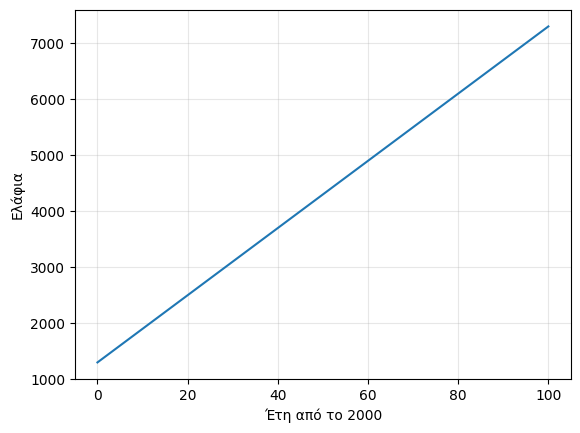

Το 2050 : 4300 ελάφια
Το 2100 : 7300 ελάφια


In [ ]:
# Κελί 1.3 - Εργαστήριο μοντέλου
# Η συνάρτηση παίρνει τον πληθυσμό αυτού του έτους (plithismos)
# και επιστρέφει τον πληθυσμό του επόμενου έτους (neos).

def neos_plithismos(plithismos):
    neos = plithismos + 60        # ΑΛΛΑΞΕ ΕΔΩ: πώς αλλάζει ο πληθυσμός σε ένα χρόνο;
    return neos

trexe(neos_plithismos, etoi=100)     # etoi: πόσα έτη προσομοιώνουμε

In [ ]:
# Κελί 1.4 - Ελέγχουμε τον κώδικα με τον τύπο
elegxos_me_tipo(neos_plithismos)

Μετά από 10 έτη: κώδικας 1900 | τύπος 1900
Μετά από 50 έτη: κώδικας 4300 | τύπος 4300
Μετά από 100 έτη: κώδικας 7300 | τύπος 7300
✔ Ο κώδικας συμφωνεί με τον τύπο.


## Συνάντηση 2: Τα δεδομένα διαφωνούν

Εκτελέστε πρώτα το **Κελί ρυθμίσεων**, αν το σημειωματάριο άνοιξε από την αρχή. Έχουμε φανταστικές παρατηρήσεις για τα έτη 2000–2020. Το κελί 2.1 τις τυπώνει σε πίνακα. Στα γραφήματα οι κύκλοι είναι οι παρατηρήσεις και οι γραμμές είναι τα μοντέλα.

In [8]:
# Κελί 2.1 - Οι παρατηρήσεις (φανταστικά δεδομένα)
print("Έτος   Ελάφια")
for i in range(21):
    print(2000 + i, "  ", paratiriseis[i])

Έτος   Ελάφια
2000    1283
2001    1320
2002    1353
2003    1399
2004    1437
2005    1449
2006    1464
2007    1519
2008    1546
2009    1587
2010    1640
2011    1651
2012    1667
2013    1701
2014    1731
2015    1713
2016    1798
2017    1814
2018    1846
2019    1864
2020    1857


arxiko_montelo : μέγιστη απόκλιση από τις παρατηρήσεις 643 ελάφια | πρόβλεψη 2050: 4300 | πρόβλεψη 2100: 7300


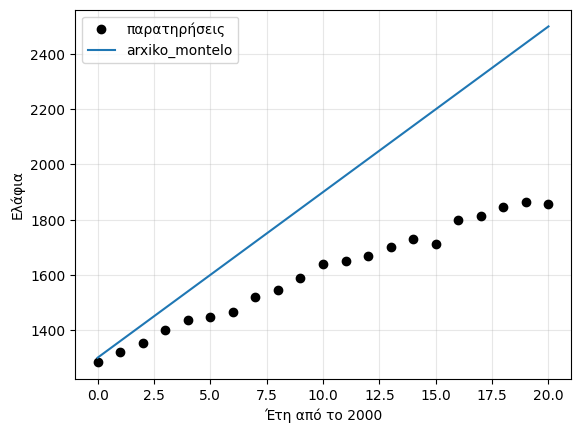

In [9]:
# Κελί 2.2 - Ο αρχικός τύπος απέναντι στις παρατηρήσεις
sygkrine(arxiko_montelo)

In [ ]:
# Κελί 2.3 - Πρώτο μοντέλο της ομάδας (Α)
def montelo_A(plithismos):
    neos = plithismos + 60        # ΑΛΛΑΞΕ ΕΔΩ
    return neos

sygkrine(montelo_A)

In [ ]:
# Κελί 2.4 - Δεύτερο μοντέλο της ομάδας (Β), με διαφορετική ιδέα από το Α
def montelo_B(plithismos):
    neos = plithismos + 60        # ΑΛΛΑΞΕ ΕΔΩ
    return neos

sygkrine(montelo_A, montelo_B)

### Ξαναχτίζουμε: το μοντέλο v3

In [ ]:
# Κελί 2.5 - Το νέο μας μοντέλο (v3)
# Βάλε εδώ τους αριθμούς του μοντέλου σου, για να τους αλλάζεις εύκολα. Παράδειγμα:
# pososto = 0.01

def neos_plithismos_v3(plithismos):
    neos = plithismos + 60        # ΑΛΛΑΞΕ ΕΔΩ: ξεκίνα από το v2 και πρόσθεσε ό,τι αποφασίσατε
    # Μπορείς να προσθέσεις γραμμές εδώ, π.χ. με if ...:
    return neos

trexe(neos_plithismos_v3, etoi=100)

In [ ]:
# Κελί 2.6 - Πολλές εκτελέσεις του ίδιου μοντέλου
trexe(neos_plithismos_v3, etoi=100, ekteleseis=30)    # ΑΛΛΑΞΕ ΕΔΩ: πόσες εκτελέσεις

In [ ]:
# Κελί 2.7 - Μέσος όρος και εύρος
statistika(neos_plithismos_v3, ekteleseis=200)

## Εφεδρικό υλικό: σκάλα βοήθειας

Τα έτοιμα κελιά δεν είναι «η σωστή απάντηση». Είναι παραδείγματα για να τα διαβάσετε, να τα αλλάξετε και να αντιγράψετε από αυτά ό,τι χρειάζεστε στο δικό σας μοντέλο.

### Βοήθεια Γ: κώδικας με κενά

In [ ]:
# Βοήθεια Γ - Συμπλήρωσε το κενό ____ και μετά εκτέλεσε
def neos_plithismos(plithismos):
    neos = plithismos + 60 - ____      # Τι χάνεται; Ένας αριθμός ή ένα ποσοστό του πληθυσμού;
    return neos

trexe(neos_plithismos)

### Βοήθεια Δ: έτοιμα κελιά

In [ ]:
# Β1 - Σταθερές απώλειες κάθε χρόνο
def voitheia_B1(plithismos):
    apoleies = 10
    return plithismos + 60 - apoleies

trexe(voitheia_B1)

In [ ]:
# Β2 - Ο πληθυσμός δεν γίνεται κάτω από 0
def voitheia_B2(plithismos):
    apoleies = 80
    return max(0, plithismos + 60 - apoleies)

trexe(voitheia_B2)

In [ ]:
# Β3 - Ποσοστιαίες απώλειες: χάνεται ένα ποσοστό του πληθυσμού κάθε χρόνο
def voitheia_B3(plithismos):
    pososto = 0.03
    return plithismos + 60 - pososto * plithismos

trexe(voitheia_B3)

In [ ]:
# Β4 - Όριο χωρητικότητας: το δάσος δεν χωράει περισσότερα ελάφια
def voitheia_B4(plithismos):
    K = 2400
    neos = plithismos + 60
    if neos > K:
        neos = K
    return neos

trexe(voitheia_B4)

In [ ]:
# Β5 - Τυχαίο γεγονός: πυρκαγιά με πιθανότητα 5% κάθε χρόνο, που σκοτώνει το 20% των ελαφιών
def voitheia_B5(plithismos):
    neos = plithismos + 60
    if random.random() < 0.05:
        neos = neos - 0.20 * neos
    return neos

trexe(voitheia_B5, ekteleseis=20)

In [ ]:
# Β6 - Όλα μαζί, με θήρα (ελάφια που επιτρέπεται να θηρεύονται κάθε χρόνο)
thira = 0          # ΑΛΛΑΞΕ ΕΔΩ

def voitheia_B6(plithismos):
    neos = plithismos + 60 - 10 - 0.01 * plithismos - thira
    if random.random() < 0.05:
        neos = neos - 0.20 * neos
    if neos > 2400:
        neos = 2400
    if neos < 0:
        neos = 0
    return neos

statistika(voitheia_B6, etoi=50)